In [1]:
import pandas as pd

import torch
from torch import nn

from kagglekit import (
    Dataset,
    LinearClassifier,
    MLP,
    Trainer,
    plot_histories,
    summarize_histories,
)

## Load Train/Val Split

In [2]:
data = torch.load('../data/train_val.pt')

X_train, X_val = data['X_train'], data['X_val']

Y_train = data['Y_train'].float().reshape(-1, 1)
Y_val = data['Y_val'].float().reshape(-1, 1)

X_train.shape, X_val.shape

(torch.Size([713, 27]), torch.Size([178, 27]))

### Majority Class Baseline

In [3]:
majority = Y_train.mean().round()
baseline_acc = (Y_val == majority).float().mean()

baseline_acc.item()

0.617977499961853

In [4]:
histories = {}

## MLP

In [5]:
dataset = Dataset(X_train, Y_train, X_val, Y_val, batch_size=32)

In [6]:
torch.manual_seed(42)

model = MLP(in_features=X_train.shape[1], out_features=1)

loss_fn = nn.BCEWithLogitsLoss()
optim = torch.optim.Adam(model.parameters(), lr=0.001)

trainer = Trainer(loss_fn, optim, max_epochs=100)

history = trainer.fit(model, dataset)

histories['M8-Adam-100-0.001'] = history

In [7]:
torch.manual_seed(42)

model = MLP(in_features=X_train.shape[1], out_features=1)

loss_fn = nn.BCEWithLogitsLoss()
optim = torch.optim.Adam(model.parameters(), lr=0.01)

trainer = Trainer(loss_fn, optim, max_epochs=100)

history = trainer.fit(model, dataset)

histories['M8-Adam-100-0.01'] = history

In [8]:
torch.manual_seed(42)

model = MLP(in_features=X_train.shape[1], out_features=1, hidden_features=16)

loss_fn = nn.BCEWithLogitsLoss()
optim = torch.optim.Adam(model.parameters(), lr=0.001)

trainer = Trainer(loss_fn, optim, max_epochs=100)

history = trainer.fit(model, dataset)

histories['M16-Adam-100-0.001'] = history

In [9]:
torch.manual_seed(42)

model = MLP(in_features=X_train.shape[1], out_features=1, hidden_features=16)

loss_fn = nn.BCEWithLogitsLoss()
optim = torch.optim.Adam(model.parameters(), lr=0.01)

trainer = Trainer(loss_fn, optim, max_epochs=100)

history = trainer.fit(model, dataset)

histories['M16-Adam-100-0.01'] = history

### Linear Reference

Best linear config from `01_linear`, trained on the same features so the MLP rows compare directly.

In [10]:
torch.manual_seed(42)

model = LinearClassifier(in_features=X_train.shape[1])

loss_fn = nn.BCEWithLogitsLoss()
optim = torch.optim.Adam(model.parameters(), lr=0.01)

trainer = Trainer(loss_fn, optim, max_epochs=100)

history = trainer.fit(model, dataset)

histories['L-Adam-100-0.01'] = history

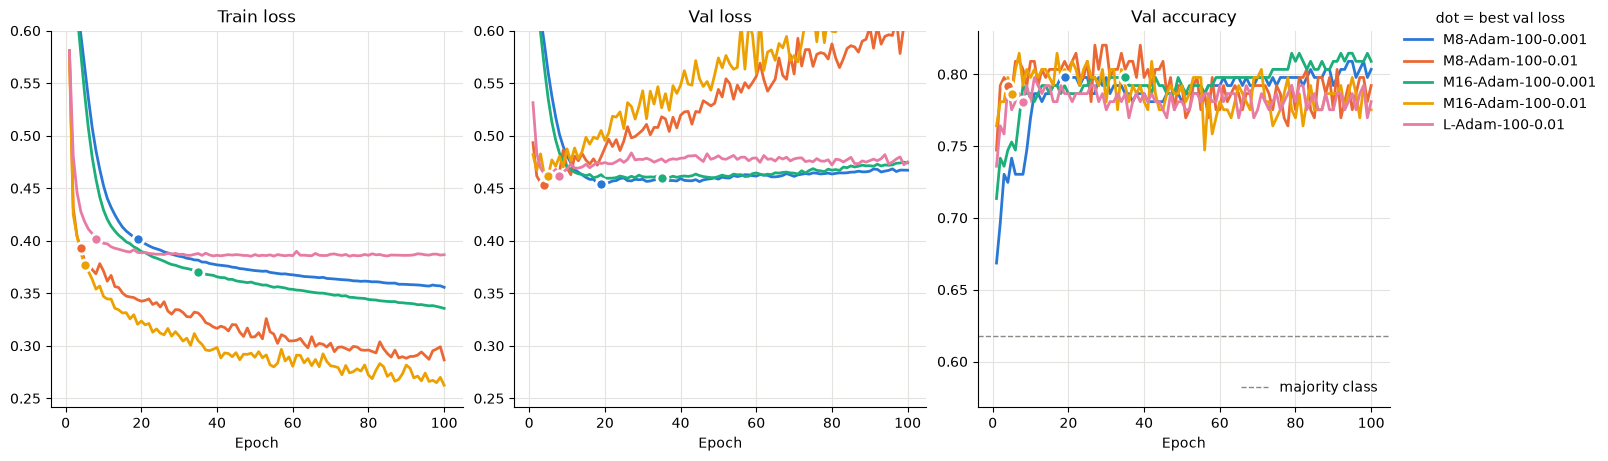

In [11]:
fig = plot_histories(histories, baseline=baseline_acc.item())

In [12]:
summarize_histories(histories).round(4)

,best_epoch,train_loss,val_loss,loss_gap,val_accuracy
M8-Adam-100-0.01,4,0.3931,0.4528,0.0598,0.7921
M8-Adam-100-0.001,19,0.4015,0.4544,0.0530,0.7978
M16-Adam-100-0.001,35,0.3706,0.4595,0.0889,0.7978
M16-Adam-100-0.01,5,0.3770,0.4617,0.0847,0.7865
L-Adam-100-0.01,8,0.4021,0.4618,0.0597,0.7809


## Full Training

In [13]:
data = torch.load('../data/train_full.pt')

X = data['X']
Y = data['Y'].float().reshape(-1, 1)

X.shape, Y.shape

(torch.Size([891, 27]), torch.Size([891, 1]))

In [14]:
dataset = Dataset(X, Y, batch_size=32)

### Training

In [15]:
torch.manual_seed(42)

model = MLP(in_features=X.shape[1], out_features=1)

loss_fn = nn.BCEWithLogitsLoss()
optim = torch.optim.Adam(model.parameters(), lr=0.001)

trainer = Trainer(loss_fn, optim, max_epochs=81)

history = trainer.fit(model, dataset)

### Prediction

In [16]:
test = torch.load('../data/test.pt')

X = test['X']
ids = test['PassengerId']

X.shape, ids.shape

(torch.Size([418, 27]), torch.Size([418]))

In [17]:
model.eval()

preds = model.predict(X.to(trainer.device)).cpu()

preds.shape

torch.Size([418])

### Submission

In [18]:
submission = pd.DataFrame({
    'PassengerId': ids,
    'Survived': preds,
})
submission.to_csv('../submissions/mlp_adam_0.001_81.csv', index=False)

submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
